In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
def circular_velocity_model1(nx, nz, dh, R, V1, V2):
    """
    Crea un modelo de velocidad con una inclusión circular.

    Parámetros
    ----------
    nx : int
        Número de muestras en x.
    nz : int
        Número de muestras en z.
    dh : float
        Espaciamiento uniforme (m).
    R : float
        Radio de la circunferencia (m).
    V1 : float
        Velocidad fuera de la circunferencia.
    V2 : float
        Velocidad dentro de la circunferencia.

    Retorna
    -------
    model : ndarray (nz, nx)
        Modelo de velocidad.
    """

    # Coordenadas
    x = np.arange(nx) * dh
    z = np.arange(nz) * dh

    X, Z = np.meshgrid(x, z)

    # Centro del modelo
    xc = (nx - 1) * dh / 2
    zc = (nz - 1) * dh / 2

    # Modelo inicial
    model = np.full((nz, nx), V1, dtype=float)

    # Máscara circular
    mask = (X - xc)**2 + (Z - zc)**2 <= R**2

    # Velocidad dentro de la circunferencia
    model[mask] = V2

    return model

In [8]:
def circular_velocity_model2(nx, nz, dh, R, V1, V2, xc=None, zc=None):
    """
    Crea un modelo de velocidad con una inclusión circular.

    Parámetros
    ----------
    nx : int
        Número de muestras en x.
    nz : int
        Número de muestras en z.
    dh : float
        Espaciamiento uniforme (m).
    R : float
        Radio de la circunferencia (m).
    V1 : float
        Velocidad fuera de la circunferencia.
    V2 : float
        Velocidad dentro de la circunferencia.
    xc : float, opcional
        Coordenada x del centro de la circunferencia (m).
        Si es None, se usa el centro del modelo.
    zc : float, opcional
        Coordenada z del centro de la circunferencia (m).
        Si es None, se usa el centro del modelo.

    Retorna
    -------
    model : ndarray (nz, nx)
        Modelo de velocidad.
    """

    # Coordenadas
    x = np.arange(nx) * dh
    z = np.arange(nz) * dh

    X, Z = np.meshgrid(x, z)

    # Si no se especifica el centro, usar el centro del modelo
    if xc is None:
        xc = (nx - 1) * dh / 2

    if zc is None:
        zc = (nz - 1) * dh / 2

    # Modelo inicial
    model = np.full((nz, nx), V1, dtype=float)

    # Máscara circular
    mask = (X - xc)**2 + (Z - zc)**2 <= R**2

    # Velocidad dentro de la circunferencia
    model[mask] = V2

    return model

In [9]:
nx = 500
nz = 174
dh = 20.0

model = circular_velocity_model1(
    nx=nx,
    nz=nz,
    dh=dh,
    R=200,
    V1=2000,
    V2=2200
)

In [14]:
model = circular_velocity_model2(
    nx=520,
    nz=270,
    dh=10,
    R=100,
    V1=2000,
    V2=2500,
    xc=500,
    zc=1000
)

In [16]:
def velocity_model3(nx, nz, dh, R, V1, V2, xc=None, zc=None,
                   perturbation="circle", sigma=None):
    """
    Crea un modelo de velocidad con una anomalía circular o gaussiana.

    Parámetros
    ----------
    nx, nz : int
        Número de muestras en x y z.
    dh : float
        Espaciamiento de la grilla (m).
    R : float
        Radio de la anomalía circular (m).

    V1 : float
        Velocidad del medio (m/s).
    V2 : float
        Velocidad máxima dentro de la anomalía (m/s).

    xc, zc : float, opcional
        Coordenadas del centro de la anomalía (m).
        Si no se especifican, se utiliza el centro del modelo.

    perturbation : str
        "circle"   -> anomalía circular de velocidad constante.
        "gaussian" -> perturbación gaussiana.

    sigma : float, opcional
        Desviación estándar de la gaussiana (m).
        Si es None, se utiliza R/2.

    Retorna
    -------
    model : ndarray (nz, nx)
        Modelo de velocidad.
    """

    # Coordenadas
    x = np.arange(nx) * dh
    z = np.arange(nz) * dh

    X, Z = np.meshgrid(x, z)

    # Centro de la anomalía
    if xc is None:
        xc = (nx - 1) * dh / 2

    if zc is None:
        zc = (nz - 1) * dh / 2

    # Modelo base
    model = np.full((nz, nx), V1, dtype=float)

    # Distancia al centro
    r2 = (X - xc)**2 + (Z - zc)**2

    # --------------------------------
    # Anomalía circular
    # --------------------------------
    if perturbation == "circle":

        mask = r2 <= R**2
        model[mask] = V2

    # --------------------------------
    # Perturbación gaussiana
    # --------------------------------
    elif perturbation == "gaussian":

        if sigma is None:
            sigma = R / 2

        delta_V = V2 - V1

        gaussian = delta_V * np.exp(
            -r2 / (2 * sigma**2)
        )

        model = V1 + gaussian

    else:
        raise ValueError(
            "perturbation debe ser 'circle' o 'gaussian'"
        )

    return model

In [43]:
model = velocity_model3(
    nx=520,
    nz=270,
    dh=10,
    R=300,
    V1=1100,
    V2=1300,
    xc=3900,
    zc=1350,
    perturbation="gaussian",
    sigma=150
)

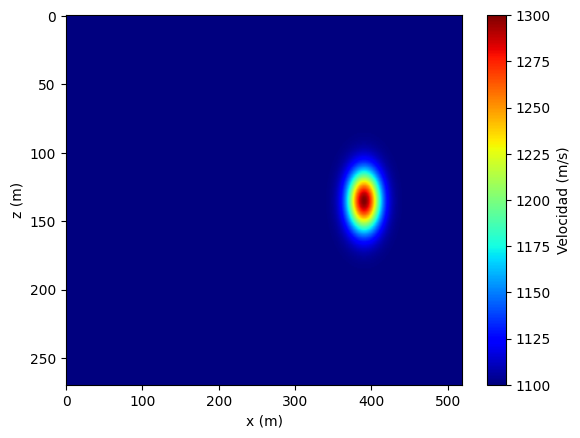

In [44]:
plt.imshow(
    model,
    aspect='auto',
    cmap='jet',
    # extent= #[0, nx*dh, nz*dh, 0]
)
plt.colorbar(label='Velocidad (m/s)')
plt.xlabel('x (m)')
plt.ylabel('z (m)')
# plt.axis('equal')
plt.show()

In [45]:
# np.transpose(model).astype('float32').tofile('modelrho.bin')

In [35]:
model.shape

(270, 520)

In [2]:
def mk_velocity_model(
    nx=200,
    nz=150,
    dx=10.0,
    dz=10.0,
    modelo_fondo=1000.0,
    dispersion=True,
    tipo="puntual",
    modelo_perturbacion=1500.0,
    ix0=None,
    iz0=None,
    radio=5
):
    """
    Crea un modelo 2D de velocidad P.

    Parámetros
    ----------
    nx, nz : número de muestras en x y z
    dx, dz : espaciamiento de la malla (m)
    modelo_fondo : velocidad de fondo (m/s)
    dispersion : True para introducir una perturbación
    tipo : "puntual" o "circular"
    modelo_perturbacion : velocidad dentro de la perturbación (m/s)
    ix0, iz0 : posición de la perturbación (índices de la malla)
    radio : radio de la inclusión circular (muestras)
    """

    # Modelo homogéneo
    modelo = np.full((nz, nx), modelo_fondo, dtype=float)

    # Posición por defecto: centro del modelo
    if ix0 is None:
        ix0 = nx // 2
    if iz0 is None:
        iz0 = nz // 2

    # Introducir perturbación si está activada
    if dispersion:
        if tipo == "puntual":
            # Una sola muestra de la malla
            modelo[iz0, ix0] = modelo_perturbacion

        elif tipo == "circular":
            # Inclusión circular
            x = np.arange(nx)
            z = np.arange(nz)
            X, Z = np.meshgrid(x, z)

            mascara = (X - ix0)**2 + (Z - iz0)**2 <= radio**2
            modelo[mascara] = modelo_perturbacion

        else:
            raise ValueError(
                "tipo debe ser 'puntual' o 'circular'"
            )

    return modelo

In [15]:
nx = 520                  # muestras horizontales
nz = 270                  # muestras verticales
dx = 10.0                 # espaciamiento horizontal (m)
dz = 10.0                 # espaciamiento vertical (m)

modelo_fondo = 1100         # velocidad de fondo (m/s)
modelo_perturbacion = 1600  # velocidad de la perturbación (m/s)

dispersion = True         # True: con perturbación
tipo = "circular"          # "puntual" o "circular"

In [16]:
modelo = mk_velocity_model(
    nx=nx,
    nz=nz,
    dx=dx,
    dz=dz,
    modelo_fondo=modelo_fondo,
    dispersion=True,
    tipo=tipo,
    modelo_perturbacion=modelo_perturbacion,
    ix0=None,
    iz0=None,
    radio=5
)

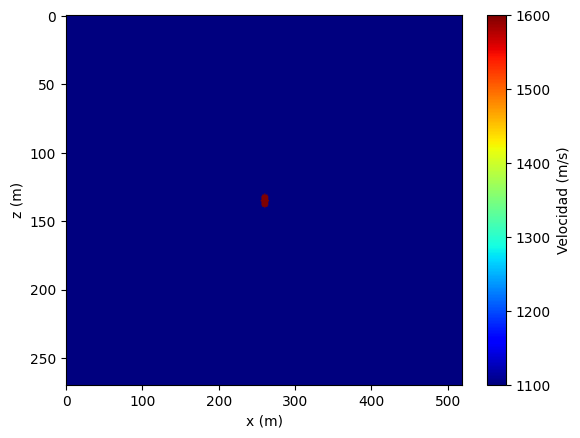

In [17]:
plt.imshow(
    modelo,
    aspect='auto',
    cmap='jet',
    # extent= #[0, nx*dh, nz*dh, 0]
)
plt.colorbar(label='Velocidad (m/s)')
plt.xlabel('x (m)')
plt.ylabel('z (m)')
# plt.axis('equal')
plt.show()

In [18]:
# np.transpose(modelo).astype('float32').tofile('model_perb_circular_rho.bin')